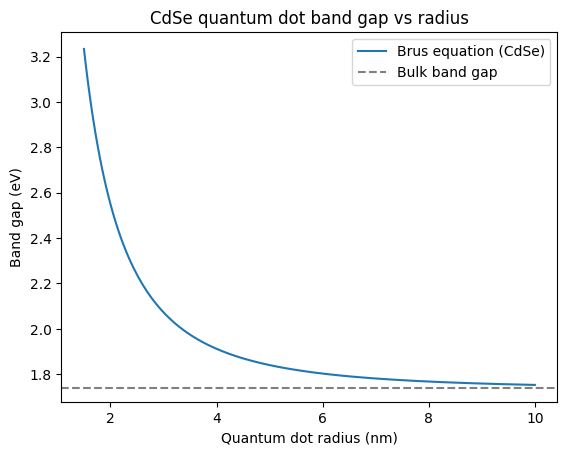

R = 2 nm: band gap = 2.55 eV, wavelength = 486 nm
R = 3 nm: band gap = 2.07 eV, wavelength = 598 nm
R = 5 nm: band gap = 1.84 eV, wavelength = 674 nm
R = 8 nm: band gap = 1.77 eV, wavelength = 701 nm


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Constants (SI units)
hbar = 1.054571817e-34    # J s
m0   = 9.1093837e-31      # kg
e    = 1.602176634e-19    # C
eps0 = 8.8541878128e-12   # F/m

# CdSe parameters (typical literature values, approximate: verify and cite your source)
Eg_bulk = 1.74            # eV, bulk band gap
me = 0.13 * m0            # electron effective mass
mh = 0.45 * m0            # hole effective mass
eps_r = 10.6              # relative dielectric constant

def brus_gap(R_nm):
    R = R_nm * 1e-9
    confinement = (hbar**2 * np.pi**2) / (2 * R**2) * (1 / me + 1 / mh)   # J
    coulomb = 1.8 * e**2 / (4 * np.pi * eps0 * eps_r * R)                 # J
    return Eg_bulk + (confinement - coulomb) / e                          # eV

R = np.linspace(1.5, 10, 200)
E = brus_gap(R)

plt.plot(R, E, label="Brus equation (CdSe)")
plt.axhline(Eg_bulk, linestyle="--", color="gray", label="Bulk band gap")
plt.xlabel("Quantum dot radius (nm)")
plt.ylabel("Band gap (eV)")
plt.title("CdSe quantum dot band gap vs radius")
plt.legend()
plt.savefig("quantum_dot_gap_vs_radius.png", dpi=200, bbox_inches="tight")
plt.show()

for r in [2, 3, 5, 8]:
    gap = brus_gap(r)
    print(f"R = {r} nm: band gap = {gap:.2f} eV, wavelength = {1239.84 / gap:.0f} nm")